# Real-time instance segmentation with YOLO26-seg, and when to call SAM

SAM-family models segment *anything you point at*, but they need a prompt and spend tens
of milliseconds per image on their encoder. A robot that must find every cup, chair and
person in a 30 Hz stream usually runs a **closed-set instance segmenter** instead: one
forward pass, a fixed list of classes, a mask per detection. This notebook uses
Ultralytics **YOLO26-seg** (n and s sizes, COCO-pretrained) and then combines both worlds:
YOLO boxes as prompts for SAM 3 when mask quality matters more than speed.

**What you will learn**

1. How YOLO-style instance segmentation produces masks: **prototype masks + per-instance
   coefficients** (YOLACT), and what is NMS-free about YOLO26.
2. How to run inference, read masks, and compute the standard **mask mAP** with
   Ultralytics' validator.
3. "Detect with YOLO, segment with SAM": how much SAM 3 improves YOLO's masks (IoU and
   boundary F) and what it costs.
4. A speed / memory comparison of every model used in this project on the same GPU.

**Prerequisites**: `make data-05_segmentation`; notebooks 01-03 (or at least the files
in `projects/05_segmentation/results/`) for the final comparison table. Hardware: RTX 5060
Laptop GPU (8 GB). Ultralytics is AGPL-3.0 licensed (see the project README).

## Setup

Imports, seeding, device and plotting style. `YOLO_AUTOINSTALL=false` stops Ultralytics
from pip-installing packages at runtime (they would bypass the repository's constraints
file), and its logger is turned down to warnings so outputs stay short.

In [1]:
# --- Setup: imports, device, paths, plotting style ---
# segkit (projects/05_segmentation/scripts/segkit.py) holds the data loaders, metrics and
# model adapters shared by all notebooks of this project, the benchmark script and the solutions.
# Photo grids are displayed with sk.show_jpeg (JPEG is ~5-10x smaller than PNG for photos);
# charts stay PNG via plt.show().
import logging
import os
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from cvlab import device as cvdevice
from cvlab import viz
from cvlab.bench import benchmark
from cvlab.device import track_vram
from cvlab.io import project_dir, repo_root

PROJECT = "05_segmentation"
os.environ["YOLO_AUTOINSTALL"] = "false"  # never pip-install at runtime
sys.path.insert(0, str(project_dir(PROJECT) / "scripts"))
import segkit as sk  # noqa: E402

device = cvdevice.setup(seed=0)
viz.set_style()
warnings.filterwarnings("ignore")  # silence library warnings in the rendered notebook
from transformers.utils import logging as hf_logging  # noqa: E402

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
RESULTS = sk.results_dir()
print("results dir:", RESULTS.relative_to(repo_root()))

from ultralytics import YOLO  # noqa: E402
from ultralytics.utils import LOGGER as YOLO_LOGGER  # noqa: E402

from cvlab.io import load_json, runs_dir, weights_dir  # noqa: E402

YOLO_LOGGER.setLevel(logging.WARNING)
NAMES = sk.coco_names()

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)


results dir: projects/05_segmentation/results


## How YOLO-seg predicts masks

The segmentation head adds two things to a YOLO detector:

* a **prototype branch** on the highest-resolution feature map that outputs $k = 32$
  image-sized prototype masks $\mathbf{P} \in \mathbb{R}^{k \times H/4 \times W/4}$,
  shared by all instances;
* for every detection, $k$ **mask coefficients** $\mathbf{c}$ next to its box and class
  scores.

The instance mask is a linear combination of prototypes, squashed and cropped to the box:

$$M = \operatorname{crop}_{\text{box}}\big(\sigma(\mathbf{c}^{\top} \mathbf{P})\big) > 0.5 .$$

This costs almost nothing on top of detection, but masks are limited by the
quarter-resolution prototypes and by what 32 basis masks can express - boundaries tend to
be smooth and slightly blobby. YOLO26 is trained with a one-to-one assignment head, so it
is **NMS-free** end-to-end (no non-maximum suppression step at inference).

In [2]:
# --- Load YOLO26n-seg and YOLO26s-seg (COCO-pretrained, 80 classes) ---
yolos = {f"YOLO26{z}-seg": YOLO(str(weights_dir("ultralytics", f"yolo26{z}-seg.pt"))) for z in ("n", "s")}
for name, m in yolos.items():
    n_params = sum(p.numel() for p in m.model.parameters()) / 1e6
    print(f"{name}: {n_params:.1f} M parameters, {len(m.names)} classes, task={m.task}")

YOLO26n-seg: 3.1 M parameters, 80 classes, task=segment
YOLO26s-seg: 11.5 M parameters, 80 classes, task=segment


## Inference on coco8-seg

`retina_masks=True` upsamples the prototypes to the original image resolution before
thresholding (sharper masks, slightly slower). Ultralytics reads NumPy images as **BGR**,
so we flip our RGB arrays.

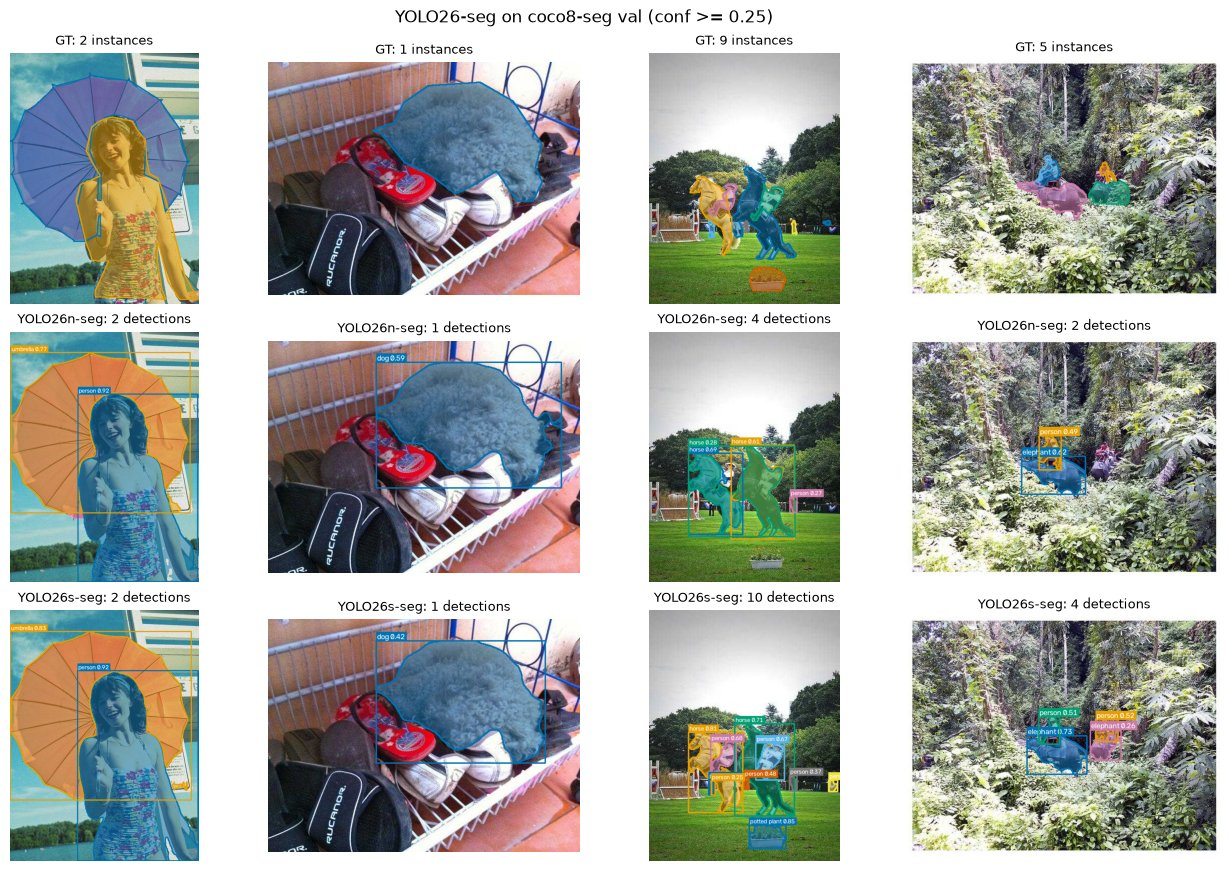

In [3]:
# --- Predict on the 4 coco8-seg val images with both sizes (conf >= 0.25) ---
val = sk.load_coco_seg("coco8-seg", splits=("val",))
fig, axes = plt.subplots(3, len(val), figsize=(3.2 * len(val), 8.6))
for col, s in enumerate(val):
    axes[0, col].imshow(viz.overlay_masks(s.image, s.masks))
    axes[0, col].set_title(f"GT: {len(s.masks)} instances", fontsize=9)
    for row, (name, m) in enumerate(yolos.items(), start=1):
        r = m.predict(np.ascontiguousarray(s.image[..., ::-1]), conf=0.25, retina_masks=True, verbose=False)[0]
        masks = r.masks.data.cpu().numpy() > 0.5 if r.masks is not None else np.zeros((0, *s.image.shape[:2]), bool)
        labels = [NAMES[int(c)] for c in r.boxes.cls]
        img = viz.overlay_masks(s.image, masks) if len(masks) else s.image
        img = viz.draw_boxes(img, r.boxes.xyxy.cpu().numpy(), labels=labels, scores=r.boxes.conf.cpu().numpy())
        axes[row, col].imshow(img)
        axes[row, col].set_title(f"{name}: {len(masks)} detections", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("YOLO26-seg on coco8-seg val (conf >= 0.25)")
viz.savefig(fig, PROJECT, "yolo26_seg_coco8")
sk.show_jpeg(fig)  # photos: JPEG keeps the notebook small

## Mask mAP with the Ultralytics validator

`model.val()` runs the standard COCO-style evaluation on a dataset YAML: predictions at
a low confidence (0.001), matching per class at IoU 0.50:0.05:0.95, 101-point AP, mean over
classes. It reports **box** mAP and **mask** mAP (mask IoU instead of box IoU). On
coco8-seg the val split has only 4 images / 13 instances, so treat it as a smoke test of
the pipeline, not as an accuracy estimate - and these COCO train2017 images were in the
models' training set.

In [4]:
# --- Ultralytics validation on coco8-seg (mask + box mAP) ---
# Runs land in runs/05_segmentation/ (gitignored); plots disabled.
val_rows = []
for name, m in yolos.items():
    met = m.val(data="coco8-seg.yaml", imgsz=640, batch=4, plots=False, verbose=False,
                project=str(runs_dir(PROJECT)), name=f"val_{name}", exist_ok=True)
    val_rows.append({"model": name, "mask mAP50-95": round(met.seg.map, 4), "mask mAP50": round(met.seg.map50, 4),
                     "box mAP50-95": round(met.box.map, 4), "box mAP50": round(met.box.map50, 4)})
yolo_val = pd.DataFrame(val_rows).set_index("model")
yolo_val

,mask mAP50-95,mask mAP50,box mAP50-95,box mAP50
model,,,,
YOLO26n-seg,0.5344,0.8253,0.6288,0.8678
YOLO26s-seg,0.6079,0.9019,0.7205,0.9705


## Speed and memory of YOLO26-seg

Latency of `model.predict` on one 640x480 image at `imgsz=640` (pre-processing, network,
mask assembly; CUDA-synchronised), plus peak VRAM. Ultralytics runs the PyTorch model in
fp32 by default here; notebook 14 (deployment) covers fp16 / TensorRT export.

In [5]:
# --- Benchmark YOLO26-seg latency (batch 1, imgsz 640) and peak VRAM ---
img_bgr = np.ascontiguousarray(val[0].image[..., ::-1])
yolo_speed = []
for name, m in yolos.items():
    torch.cuda.empty_cache()
    with track_vram() as mem:
        b = benchmark(m.predict, img_bgr, imgsz=640, conf=0.25, verbose=False, warmup=10, iters=50)
        b_retina = benchmark(m.predict, img_bgr, imgsz=640, conf=0.25, retina_masks=True, verbose=False,
                             warmup=5, iters=30)
    yolo_speed.append({"model": name, "ms/image": round(b["mean_ms"], 1), "FPS": round(b["fps"], 0),
                       "ms/image (retina masks)": round(b_retina["mean_ms"], 1),
                       "peak VRAM (MiB)": round(mem.peak_mb, 0)})
yolo_speed = pd.DataFrame(yolo_speed).set_index("model")
yolo_speed

,ms/image,FPS,ms/image (retina masks),peak VRAM (MiB)
model,,,,
YOLO26n-seg,4.9,203.0,4.6,176.0
YOLO26s-seg,7.4,136.0,7.6,197.0


## Detect with YOLO, segment with SAM 3

When mask quality matters (grasp planning, measuring an object's footprint), a common
pattern is to keep the fast closed-set detector for *what* and *where*, and give its
boxes to a promptable segmenter for the *exact shape*. We run YOLO26n-seg (conf $\geq$
0.25) on all 128 coco128-seg images, match each detection to a GT instance of the same
class by **box IoU** $\geq 0.5$ (so neither mask decides the matching), and compare on the
matched set:

* mask IoU and boundary F of YOLO's own (retina) mask, vs
* mask IoU and boundary F of the SAM 3 tracker mask prompted with YOLO's box.

In [6]:
# --- YOLO26n-seg boxes -> SAM 3 masks on coco128-seg; compare mask quality on matched detections ---
from cvlab.metrics import box_iou

coco128 = sk.load_coco_seg("coco128-seg", splits=("train2017",))
yolo = yolos["YOLO26n-seg"]
torch.cuda.empty_cache()
with track_vram() as mem_refine:
    sam3 = sk.PromptableSegmenter(sk.SAM3_ID, device=str(device))
    refine_rows = []
    for s in coco128:
        r = yolo.predict(np.ascontiguousarray(s.image[..., ::-1]), conf=0.25, retina_masks=True, verbose=False)[0]
        if r.masks is None or len(s.masks) == 0:
            continue
        boxes, cls = r.boxes.xyxy.cpu().numpy(), r.boxes.cls.cpu().numpy().astype(int)
        ymasks = r.masks.data.cpu().numpy() > 0.5
        ious = box_iou(boxes, s.boxes) * (cls[:, None] == s.classes[None, :])  # same class only
        taken = np.zeros(len(s.masks), bool)
        pairs = []
        for i in np.argsort(-r.boxes.conf.cpu().numpy()):  # greedy, by confidence
            cand = np.where(taken, -1, ious[i])
            j = int(np.argmax(cand))
            if cand[j] >= 0.5:
                taken[j] = True
                pairs.append((i, j))
        if not pairs:
            continue
        sam3.set_image(s.image)
        smasks, _, _ = sam3.predict(boxes=[boxes[i].tolist() for i, _ in pairs], multimask=False)
        for (i, j), sm in zip(pairs, smasks[:, 0]):
            g = s.masks[j]
            refine_rows.append({"image": s.name, "det": int(i), "gt": int(j), "class": NAMES[cls[i]],
                                "area": int(g.sum()),
                                "size": "small" if g.sum() < 32**2 else "medium" if g.sum() < 96**2 else "large",
                                "J YOLO": sk.j_measure(ymasks[i], g), "J SAM 3": sk.j_measure(sm, g),
                                "F YOLO": sk.f_measure(ymasks[i], g), "F SAM 3": sk.f_measure(sm, g)})
refine = pd.DataFrame(refine_rows)
refine.to_csv(RESULTS / "nb04_yolo_sam3_refine.csv", index=False, float_format="%.4f")
print(f"{len(refine)} matched detections on {refine.image.nunique()} images; "
      f"peak VRAM (YOLO26n + SAM 3 tracker) {mem_refine.peak_mb:.0f} MiB")
refine.groupby("size")[["J YOLO", "J SAM 3", "F YOLO", "F SAM 3"]].mean().round(3)

469 matched detections on 123 images; peak VRAM (YOLO26n + SAM 3 tracker) 1461 MiB


,J YOLO,J SAM 3,F YOLO,F SAM 3
size,,,,
large,0.835,0.808,0.803,0.784
medium,0.793,0.808,0.913,0.937
small,0.709,0.742,0.982,0.988


A few examples where SAM 3 changed YOLO's mask the most (largest IoU gain and largest IoU
loss), so the improvement and the failure modes are both visible:

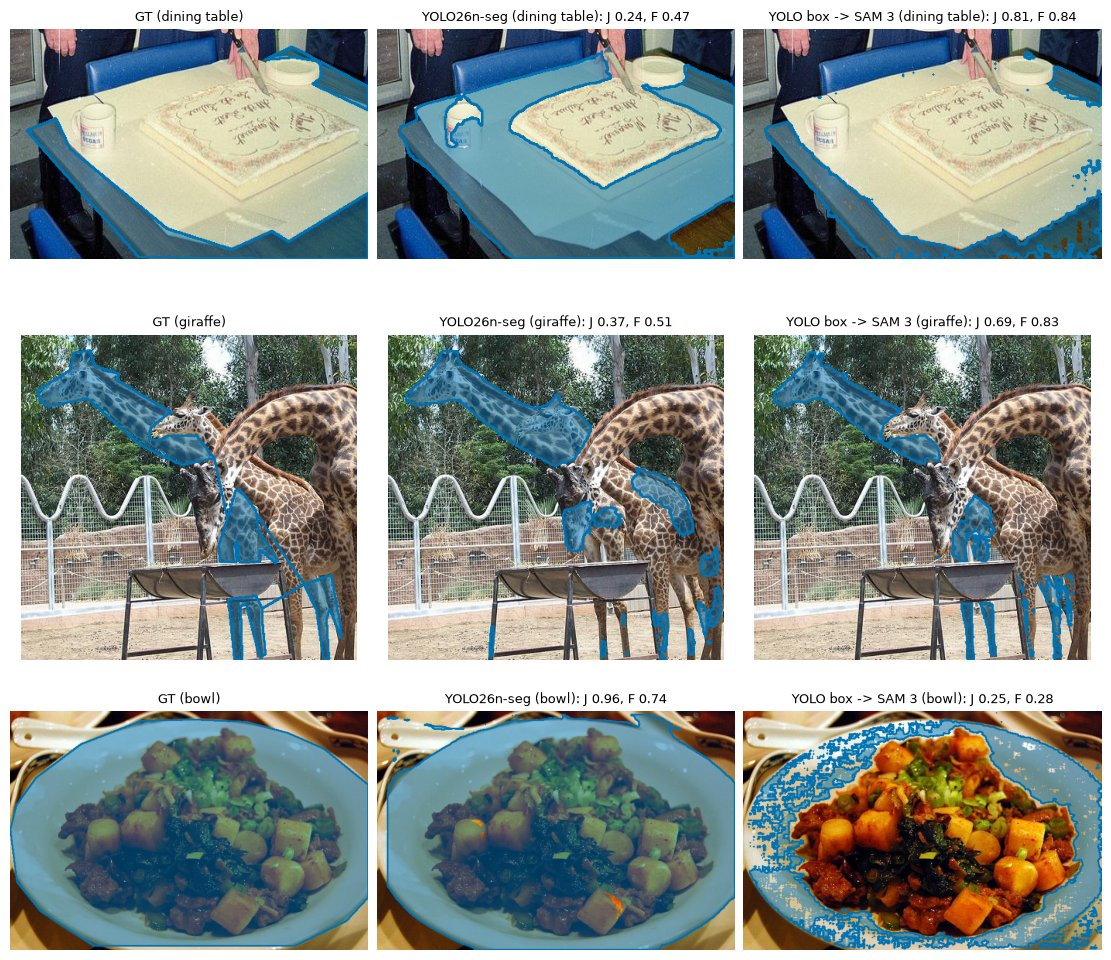

In [7]:
# --- Qualitative: largest gains and losses of SAM 3 over YOLO26n-seg masks ---
refine["gain"] = refine["J SAM 3"] - refine["J YOLO"]
picks = pd.concat([refine.nlargest(2, "gain"), refine.nsmallest(1, "gain")])
by_name = {s.name: s for s in coco128}
fig, axes = plt.subplots(len(picks), 3, figsize=(11, 3.4 * len(picks)))
for row, (_, p) in enumerate(picks.iterrows()):
    s = by_name[p.image]
    r = yolo.predict(np.ascontiguousarray(s.image[..., ::-1]), conf=0.25, retina_masks=True, verbose=False)[0]
    ym = r.masks.data.cpu().numpy() > 0.5
    g, yi = s.masks[int(p["gt"])], int(p["det"])  # same (deterministic) prediction as in the study
    sam3.set_image(s.image)
    sm = sam3.predict(boxes=[r.boxes.xyxy[yi].tolist()], multimask=False)[0][0, 0]
    x1, y1, x2, y2 = (int(v) for v in sk.mask_to_box(g))
    win = (slice(max(0, y1 - 20), y2 + 20), slice(max(0, x1 - 20), x2 + 20))
    for col, (title, m) in enumerate([("GT", g), ("YOLO26n-seg", ym[yi]), ("YOLO box -> SAM 3", sm)]):
        axes[row, col].imshow(viz.overlay_masks(s.image, m[None])[win])
        sub = "" if col == 0 else f": J {sk.j_measure(m, g):.2f}, F {sk.f_measure(m, g):.2f}"
        axes[row, col].set_title(f"{title} ({p['class']}){sub}", fontsize=9)
        axes[row, col].axis("off")
viz.savefig(fig, PROJECT, "yolo_vs_sam3_masks")
sk.show_jpeg(fig)

## Results

Two results: (1) how much the SAM 3 refinement improves YOLO26n-seg masks, by object size;
(2) the speed / memory table of every model in this project, collected from the result
files of notebooks 01-03 and the coco128-seg benchmarks plus the measurements above. All
numbers: RTX 5060 Laptop GPU (8 GB), PyTorch 2.11, SAM models in bfloat16, YOLO in fp32,
batch 1.

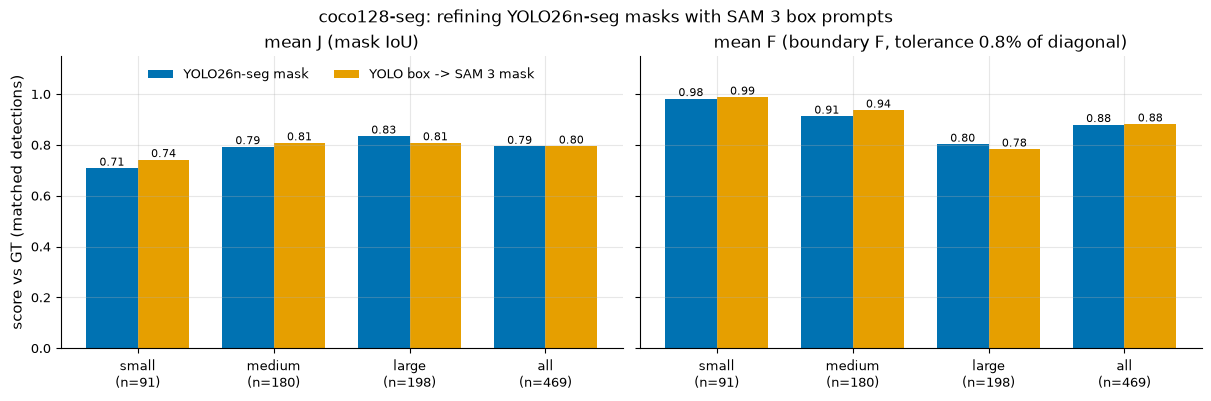

In [8]:
# --- Figure: YOLO26n-seg masks vs SAM 3 refinement (mean J and F by object size) ---
sizes = ["small", "medium", "large", "all"]
agg = refine.groupby("size")[["J YOLO", "J SAM 3", "F YOLO", "F SAM 3"]].mean()
agg.loc["all"] = refine[["J YOLO", "J SAM 3", "F YOLO", "F SAM 3"]].mean()
counts = refine["size"].value_counts()
counts["all"] = len(refine)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), sharey=True)
for ax, metric in zip(axes, ["J", "F"]):
    for i, src in enumerate(["YOLO", "SAM 3"]):
        xs = np.arange(len(sizes)) + (i - 0.5) * 0.38
        vals = agg.loc[sizes, f"{metric} {src}"]
        ax.bar(xs, vals, 0.38, label="YOLO26n-seg mask" if src == "YOLO" else "YOLO box -> SAM 3 mask",
               color=viz.color(i, unit=True))
        for x, v in zip(xs, vals):
            ax.text(x, v + 0.01, f"{v:.2f}", ha="center", fontsize=8)
    ax.set_xticks(range(len(sizes)), [f"{z}\n(n={counts.get(z, 0)})" for z in sizes])
    ax.set_title(f"mean {'J (mask IoU)' if metric == 'J' else 'F (boundary F, tolerance 0.8% of diagonal)'}")
    ax.set_ylim(0, 1.15)  # headroom for the legend above the bars
axes[0].set_ylabel("score vs GT (matched detections)")
axes[0].legend(loc="upper center", ncol=2)
fig.suptitle("coco128-seg: refining YOLO26n-seg masks with SAM 3 box prompts")
viz.savefig(fig, PROJECT, "yolo_sam3_refine")
plt.show()

The project-wide speed / memory table. "Latency" is per image for single-pass models,
per frame for video, per prompt for text pipelines; "quality" is each model's headline
metric in this project (different tasks, so compare within a task only).

In [9]:
# --- Project-wide speed / VRAM / quality table (collected from all result files) ---
nb1 = pd.read_csv(RESULTS / "nb01_summary.csv", index_col=0)
nb3 = pd.read_csv(RESULTS / "nb03_davis_summary.csv")
text = load_json(RESULTS / "text_coco128-seg.json")["methods"]
rows = []
for m, r in nb1.iterrows():
    rows.append({"model / pipeline": m, "task": "promptable image seg (click/box)", "params (M)": r["params (M)"],
                 "latency (ms)": r["encoder ms"] + r["decoder ms"], "latency unit": "image + 1 click",
                 "peak VRAM (MiB)": r["peak VRAM (MiB)"], "quality": f"box mIoU {r['mIoU box']:.3f} (coco128)"})
text_units = {"SAM 3 (text)": f"phrase, cached image (+{text['SAM 3 (text)']['image_encoder_ms']:.0f} ms/image enc.)",
              "Grounding DINO-T + SAM 2.1-S": "phrase (GDINO pass + SAM 2.1 decode)"}
for m in ["SAM 3 (text)", "Grounding DINO-T + SAM 2.1-S"]:
    rows.append({"model / pipeline": m, "task": "text-prompted instance seg", "params (M)": text[m]["params_M"],
                 "latency (ms)": text[m]["ms_per_prompt"], "latency unit": text_units[m],
                 "peak VRAM (MiB)": text[m]["peak_vram_MiB"], "quality": f"mask AP {text[m]['AP']:.3f} (coco128)"})
for name in yolos:
    t = text[f"{name} (closed set)"]
    rows.append({"model / pipeline": name, "task": "closed-set instance seg (80 COCO classes)",
                 "params (M)": t["params_M"], "latency (ms)": yolo_speed.loc[name, "ms/image"],
                 "latency unit": "image", "peak VRAM (MiB)": yolo_speed.loc[name, "peak VRAM (MiB)"],
                 "quality": f"mask AP {t['AP']:.3f} (coco128, oracle classes)"})
vid = nb3[nb3.prompt.isin(["mask", "text"])].groupby("model").agg(
    {"ms/frame": "mean", "peak VRAM (MiB)": "max", "JF_mean": "mean"})
for m, r in vid.iterrows():
    rows.append({"model / pipeline": f"{m} video", "task": "video object seg (DAVIS)",
                 "params (M)": np.nan, "latency (ms)": round(r["ms/frame"], 1), "latency unit": "frame",
                 "peak VRAM (MiB)": r["peak VRAM (MiB)"], "quality": f"J&F {r['JF_mean']:.3f} (2 DAVIS seqs)"})
overview = pd.DataFrame(rows).set_index("model / pipeline")
overview["latency (ms)"] = overview["latency (ms)"].astype(float).round(1)
overview.to_csv(RESULTS / "nb04_overview.csv")
overview

,task,params (M),latency (ms),latency unit,peak VRAM (MiB),quality
model / pipeline,,,,,,
SAM 2.1-T,promptable image seg (click/box),31.4,37.3,image + 1 click,331.0,box mIoU 0.770 (coco128)
SAM 2.1-S,promptable image seg (click/box),38.5,43.0,image + 1 click,346.0,box mIoU 0.772 (coco128)
SAM 2.1-B+,promptable image seg (click/box),73.3,68.9,image + 1 click,440.0,box mIoU 0.778 (coco128)
SAM 3,promptable image seg (click/box),458.3,346.7,image + 1 click,1163.0,box mIoU 0.781 (coco128)
SAM 3 (text),text-prompted instance seg,840.4,52.3,"phrase, cached image (+367 ms/image enc.)",2424.0,mask AP 0.495 (coco128)
Grounding DINO-T + SAM 2.1-S,text-prompted instance seg,210.8,366.0,phrase (GDINO pass + SAM 2.1 decode),2365.0,mask AP 0.428 (coco128)
YOLO26n-seg,closed-set instance seg (80 COCO classes),3.1,4.9,image,176.0,"mask AP 0.427 (coco128, oracle classes)"
YOLO26s-seg,closed-set instance seg (80 COCO classes),11.5,7.4,image,197.0,"mask AP 0.472 (coco128, oracle classes)"
SAM 2.1-S video,video object seg (DAVIS),NaN,124.8,frame,1014.0,J&F 0.973 (2 DAVIS seqs)


The same latencies and memory footprints as a chart (log-scale latency):

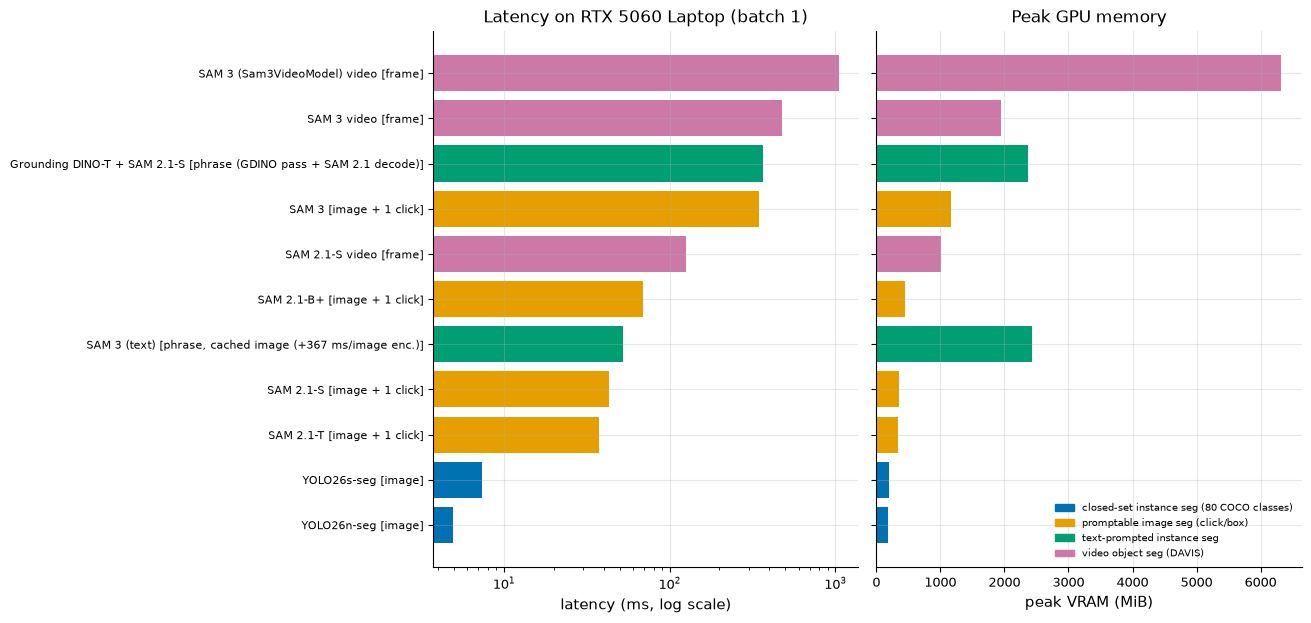

In [10]:
# --- Figure: latency (log scale) and peak VRAM of every model / pipeline ---
ov = overview.sort_values("latency (ms)")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 0.42 * len(ov) + 1.5), sharey=True)
tasks = list(dict.fromkeys(ov["task"]))
colors = [viz.color(tasks.index(t), unit=True) for t in ov["task"]]
ax1.barh(range(len(ov)), ov["latency (ms)"], color=colors)
ax1.set_xscale("log")
ax1.set_xlabel("latency (ms, log scale)")
ax1.set_yticks(range(len(ov)), [f"{m} [{u}]" for m, u in zip(ov.index, ov["latency unit"])], fontsize=8)
ax1.set_title("Latency on RTX 5060 Laptop (batch 1)")
ax2.barh(range(len(ov)), ov["peak VRAM (MiB)"], color=colors)
ax2.set_xlabel("peak VRAM (MiB)")
ax2.set_title("Peak GPU memory")
from matplotlib.patches import Patch

ax2.legend(handles=[Patch(color=viz.color(i, unit=True), label=t) for i, t in enumerate(tasks)],
           fontsize=7, loc="lower right")
viz.savefig(fig, PROJECT, "speed_vram_overview")
plt.show()

Final numbers of this notebook (YOLO26-seg validation, speed and the refinement study):

In [11]:
# --- Summary table of this notebook's own measurements ---
ref = refine[["J YOLO", "J SAM 3", "F YOLO", "F SAM 3"]].mean().round(4).to_dict()
refine_row = pd.DataFrame(
    [{**ref, "matched detections": len(refine), "peak VRAM (MiB)": round(mem_refine.peak_mb, 0)}],
    index=["YOLO26n-seg -> SAM 3 refine (coco128, matched)"])
summary = pd.concat([yolo_val.join(yolo_speed), refine_row])
summary

,mask mAP50-95,mask mAP50,box mAP50-95,box mAP50,ms/image,FPS,ms/image (retina masks),peak VRAM (MiB),J YOLO,J SAM 3,F YOLO,F SAM 3,matched detections
YOLO26n-seg,0.5344,0.8253,0.6288,0.8678,4.9,203.0,4.6,176.0,NaN,NaN,NaN,NaN,NaN
YOLO26s-seg,0.6079,0.9019,0.7205,0.9705,7.4,136.0,7.6,197.0,NaN,NaN,NaN,NaN,NaN
"YOLO26n-seg -> SAM 3 refine (coco128, matched)",NaN,NaN,NaN,NaN,NaN,NaN,NaN,1461.0,0.7943,0.7955,0.88,0.8823,469.0


### Takeaways

* **YOLO26-seg is the only model here that fits a real-time loop.** One 640x480 image
  takes 4.9 ms with YOLO26n-seg (203 FPS) and 7.4 ms with YOLO26s-seg (136 FPS), including
  pre- and post-processing, at 176 / 197 MiB peak VRAM. That is about 70x less than SAM 3
  needs for one image and one click (346.7 ms). `retina_masks=True` cost nothing measurable
  in this run (4.6 vs 4.9 ms and 7.6 vs 7.4 ms are within run-to-run noise).
* **The coco8-seg mAP is a pipeline check, not an accuracy estimate.** YOLO26s-seg reaches
  mask mAP50-95 0.6079 vs 0.5344 for YOLO26n-seg, but on 4 images / 13 instances that the
  models saw in training. The coco128-seg benchmark of notebook 02 (mask AP 0.4724 vs
  0.4268 with oracle classes) points the same way on more data.
* **On average, refining YOLO masks with SAM 3 changes almost nothing.** On 469 matched
  detections mean J goes from 0.7943 to 0.7955 and boundary F from 0.8800 to 0.8823; 54% of
  the detections improve. The gain is concentrated on small (J 0.709 -> 0.742) and medium
  objects (J 0.793 -> 0.808, F 0.913 -> 0.937), where YOLO's quarter-resolution prototypes
  are coarsest. Large objects get worse (J 0.835 -> 0.808).
* **The failures are about what a box means, not about mask sharpness.** SAM 3 recovers
  shapes the 32 prototypes cannot express: the cluttered dining table (J 0.24 -> 0.81) and
  the occluded giraffe split into two parts (J 0.37 -> 0.69). On the bowl it keeps only the
  ceramic rim and leaves out the food, while COCO, and YOLO trained on COCO, count the
  contents as part of the bowl (J 0.96 -> 0.25). A box prompt does not carry the labelling
  convention of the dataset.
* **Refine selectively.** The refinement adds SAM 3's image encoder (343.4 ms in notebook
  01) to every image and raises peak VRAM to 1461 MiB. Run it for small objects, or for
  the one object a grasp planner is about to touch, not for every detection.
* **Project-wide**, latency spans more than two orders of magnitude, from 4.9 ms per image
  (YOLO26n-seg) to 1054.4 ms per frame (`Sam3VideoModel` with text prompts, mean of two
  clips), and peak VRAM from 176 to 6325 MiB. On an 8 GB robot computer a sensible split is
  YOLO26-seg for the always-on loop, SAM 2.1-T/S for click- or box-to-mask and video
  tracking, and SAM 3 when the concept is open-vocabulary or small objects matter.

## Exercises

Solutions: `projects/05_segmentation/solutions/` (run them from the repository root).

**Exercise 1 - fine-tune YOLO26n-seg.** Fine-tune the COCO-pretrained YOLO26n-seg on
coco8-seg for 20 epochs (`model.train(data="coco8-seg.yaml", epochs=20, imgsz=640,
batch=4, project=str(runs_dir(PROJECT)))`) and compare the validation mask mAP with the
pretrained model. Why is the result not meaningful as an accuracy estimate (hint: which
images are in train and val)?

In [12]:
# --- Exercise 1: short fine-tune of YOLO26n-seg on coco8-seg ---
# TODO: m = YOLO(weights_dir("ultralytics", "yolo26n-seg.pt")); m.train(...); m.val(...)
#       and compare met.seg.map with yolo_val.loc["YOLO26n-seg", "mask mAP50-95"].

**Exercise 2 - mask resolution.** Compare YOLO26n-seg masks with `retina_masks=False`
(prototype resolution, upsampled by Ultralytics) and `retina_masks=True` on the matched
coco128-seg detections: mean J, mean F and latency. Is the boundary gain worth the time?

In [13]:
# --- Exercise 2: retina masks vs default masks ---
# TODO: re-run the matching loop with retina_masks=False (resize masks to the image size
#       with cv2.resize(..., interpolation=cv2.INTER_NEAREST) if needed) and compare.

**Exercise 3 - a cheaper refiner.** Replace the SAM 3 tracker by SAM 2.1-Tiny
(`sk.PromptableSegmenter(sk.SAM2_IDS["tiny"])`) in the refinement study. How much of the
boundary gain do you keep, and how much faster is it?

In [14]:
# --- Exercise 3: YOLO26n-seg boxes -> SAM 2.1-Tiny masks ---
# TODO: rerun the refinement loop with a SAM 2.1-Tiny segmenter and time set_image + predict.